**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**07 | Matched Nested GroupKFold and Fixed-Update Training**

![HARTH grouped nested training and fixed-update workflow](../../images/07_consolidated_workflow.svg)

**Objective:** Compare nested 500- and 1,000-window-per-participant Train cohorts under two complementary grouped Development experiments: Random Forest versus five-epoch weighted CNN comparison, and a fixed 400-optimiser-update weighted CNN comparison.

**Dataset:** Official NTNU AI Lab HARTH v2.0. Six 50 Hz lower-back/thigh acceleration channels are segmented into label-pure 100-sample windows with stride 50. The eight-class Development population comprises 29 participants; reserved S023 and S032 are excluded.

**Shared design:** Reconstruct 14,201 base and 28,201 expanded source windows once, using strict nested selection. Both experiments use three whole-participant GroupKFold partitions and only base-cap source windows for matched Validation. Expanded windows from held-out participants never enter training.

**Protocol A:** RF 500, RF 1,000, weighted CNN 500 and weighted CNN 1,000; five epochs per CNN, which does not control optimiser updates.

**Protocol B:** Weighted CNN 500 and 1,000 fitted for exactly 400 optimiser updates each; evaluate at 100, 200, 300 and 400 steps. Equal updates do not imply equal unique-source-window exposures.

**Boundary:** Development-only evidence; report numerical findings after the integrated notebook has run and its `07_cv_` and `07_steps_` outputs have been checked.


**00. Colab Repository Setup**

Load or create the public repository checkout before running the study-specific modules.


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/human-movement-intelligence


**01. Imports and Research Environment**

Load reusable HARTH, grouped evaluation, neural training, plotting and output helpers.


In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ---------------- 3. Machine Learning and Evaluation Metrics -----------------
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, balanced_accuracy_score

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4),
)

# ------------------ 5. HARTH and Shared Research Utilities -------------------
from harth_data import (
    HARTH_SUBJECTS, SENSOR_COLUMNS, ACTIVITY_NAMES,
    prepare_harth_nested_window_cohort,
)
from core.training_scale_cv import evaluate_nested_training_group_cv
from core.temporal_cnn import train_temporal_cnn_fixed_steps
from core.ml_baselines import (
    evaluate_predictions_by_subject, classification_class_report,
)
from core.group_cross_validation import compare_models_by_subject
from core.output_download import download_outputs_from_colab

# ------------------- 6. Training Device and Output Folder --------------------
from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Research output directory:", output_dir)


Repository updated.
Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.14.1+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92800
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output


**02. Build Shared Nested Development Windows**

Load the official source recordings once, construct label-pure temporal windows by participant and preserve the 500-cap source rows inside each expanded 1,000-cap cohort.


In [3]:
# ================ 02. Build Shared Nested Development Windows ================

# ----------------- 1. Configure Development and Test Cohorts -----------------
RESERVED_TEST = {"S023", "S032"}
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
TASK_CLASSES = tuple(range(1, 9))

# ------------------ 2. Build Strictly Nested Source Windows ------------------
X, metadata, overview = prepare_harth_nested_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES,
    base_cap=500, expanded_cap=1000,  # Include all original cap-500 windows in the larger cohort.
    window_size=100, step_size=50, sampling_rate=50,
)
if set(metadata["subject_id"]) != set(DEVELOPMENT_SUBJECTS):
    raise ValueError("Development subject identities do not match the cohort.")
if set(metadata["subject_id"]) & RESERVED_TEST:
    raise ValueError("Reserved participants were included.")

# ----------------- 3. Inspect Base Windows and Source Counts -----------------
if len(X) != len(metadata) or X.shape[1:] != (len(SENSOR_COLUMNS), 100):
    raise ValueError("Nested signals and metadata do not align.")
display(overview)
print("Expanded signal windows:", X.shape)
print("Original base validation candidate windows:", int(metadata["in_base_500"].sum()))

# --------------------- 4. Share Original Source Indices ----------------------
base_mask = metadata["in_base_500"].to_numpy(dtype=bool)
base_rows = np.flatnonzero(base_mask)
labels = metadata["label"].to_numpy()
subjects = metadata["subject_id"].to_numpy()
print("Base and expanded Development windows:", len(base_rows), len(X))


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candid

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 2

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343


,subject_id,eligible_windows,base_windows,expanded_windows,new_training_windows
0,S006,6708,500,1000,500
1,S008,7392,500,1000,500
2,S009,201,201,201,0
3,S010,6077,500,1000,500
4,S012,7309,500,1000,500
5,S013,6402,500,1000,500
6,S014,6299,500,1000,500
7,S015,7453,500,1000,500
8,S016,6272,500,1000,500
9,S017,6678,500,1000,500


Expanded signal windows: (28201, 6, 100)
Original base validation candidate windows: 14201
Base and expanded Development windows: 14201 28201


**03. Inspect Class Support in Both Nested Cohorts**

Report eight-class support for base and expanded windows. This identifies changed source coverage but is not itself an estimate of classification performance.


In [4]:
# ============= 03. Inspect Class Support in Both Nested Cohorts ==============

# ---------------- 1. Compare Base and Expanded Class Support -----------------
counts = pd.DataFrame({
    "base": metadata.loc[metadata["in_base_500"], "label"].value_counts(),
    "expanded": metadata["label"].value_counts(),
}).reindex(TASK_CLASSES).fillna(0).astype(int)
counts.index = [ACTIVITY_NAMES[code] for code in TASK_CLASSES]

# -------------------- 2. Inspect Nested Activity Coverage --------------------
counts["additional"] = counts["expanded"] - counts["base"]
display(counts)

if not (counts["base"] > 0).all():
    raise ValueError("At least one activity is absent from the base cohort.")
if not (counts["additional"] >= 0).all():
    raise ValueError("Nested expansion decreased source activity coverage.")


,base,expanded,additional
Walking,3591,7101,3510
Running,1028,2050,1022
Shuffling,219,423,204
Stairs ascending,192,372,180
Stairs descending,182,355,173
Standing,2227,4380,2153
Sitting,5599,11196,5597
Lying,1163,2324,1161


**04. Run Four-Model Nested GroupKFold**

Three participant-disjoint folds evaluate RF 500/1,000 and weighted CNN 500/1,000 on the identical held-out base windows. Scaling and CNN class weights are derived within each fold's Train partition; CNNs use five epochs, not an equal update budget.


In [5]:
# =================== 04. Run Four-Model Nested GroupKFold ====================

FOLDS = 3  # Subject-Disjoint Fold Configuration
EPOCHS = 5 # CNN Training Budget

# ----------------- 1. Evaluate Nested GroupKFold Conditions ------------------
cv_fold_results, cv_subject_results, cv_class_results, cv_prediction_records = evaluate_nested_training_group_cv(
    windows=X,
    metadata=metadata,
    classes=TASK_CLASSES,
    channel_names=SENSOR_COLUMNS,
    n_splits=FOLDS,
    epochs=EPOCHS,
    batch_size=128,
    learning_rate=1e-3,
    random_state=42,
    device=DEVICE,
    forbidden_subject_ids=RESERVED_TEST,  # Protect original reserved Test participants.
)

# --------------------- 2. Review Fold and Model Results ----------------------
display(cv_fold_results[[
    "fold", "model", "train_subjects", "validation_subjects",
    "train_windows", "validation_windows", "macro_f1", "balanced_accuracy",
]].round(4))

# -------------------- 3. Confirm Matched Out-of-Fold Rows --------------------
base_sources = set(base_rows.tolist())
for name, evidence in cv_prediction_records.groupby("model"):
    if not evidence["source_row"].is_unique or set(evidence["source_row"]) != base_sources:
        raise ValueError(f"Unmatched held-out source rows: {name}.")
if set(cv_subject_results["subject_id"]) != set(DEVELOPMENT_SUBJECTS):
    raise ValueError("Not all Development participants were assessed.")


Input windows: (28201, 6, 100)
Feature matrix: (28201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Fold 1/3: 19 Train people, 10 Validation people; 9201 vs 18201 Train windows
Fold 1: fitting Weighted CNN 500
Epoch 1/5 | loss=1.0101 | validation Macro F1=0.5766
Epoch 2/5 | loss=0.5557 | validation Macro F1=0.6125
Epoch 3/5 | loss=0.4243 | validation Macro F1=0.7223
Epoch 4/5 | loss=0.3267 | validation Macro F1=0.7530
Epoch 5/5 | loss=0.2661 | validation Macro F1=0.7273
Fold 1: fitting Weighted CNN 1000
Epoch 1/5 | loss=0.7780 | validation Macro F1=0.6783
Epoch 2/5 | loss=0.3817 | validation Macro F1=0.7440
Epoch 3/5 | loss=0.2573 | validation Macro F1=0.7822
Epoch 4/5 | loss=0.2030 | validation Macro F1=0.7439
Epoch 5/5 | loss=0.1794 | validation Macro F1=0.7615
Fold 2/3: 19 Train people, 10 Validation people; 9500 vs 19000 Train windows
Fold 2: fitting Weighted CNN 500
Epoch 1/5 | loss=0.9811 | validation Macro F1=0.5875
Epoch 2/5 | loss=0.5193 | validation Macro F1=0

,fold,model,train_subjects,validation_subjects,train_windows,validation_windows,macro_f1,balanced_accuracy
0,1,RF 500,"S008, S009, S010, S013, S014, S016, S017, S019...","S006, S012, S015, S018, S021, S025, S028, S031...",9201,5000,0.7969,0.8368
1,1,RF 1000,"S008, S009, S010, S013, S014, S016, S017, S019...","S006, S012, S015, S018, S021, S025, S028, S031...",18201,5000,0.7795,0.8265
2,1,Weighted CNN 500,"S008, S009, S010, S013, S014, S016, S017, S019...","S006, S012, S015, S018, S021, S025, S028, S031...",9201,5000,0.7273,0.8198
3,1,Weighted CNN 1000,"S008, S009, S010, S013, S014, S016, S017, S019...","S006, S012, S015, S018, S021, S025, S028, S031...",18201,5000,0.7615,0.8418
4,2,RF 500,"S006, S008, S012, S013, S015, S016, S018, S019...","S009, S010, S014, S017, S020, S024, S027, S030...",9500,4701,0.7669,0.7608
5,2,RF 1000,"S006, S008, S012, S013, S015, S016, S018, S019...","S009, S010, S014, S017, S020, S024, S027, S030...",19000,4701,0.7844,0.7744
6,2,Weighted CNN 500,"S006, S008, S012, S013, S015, S016, S018, S019...","S009, S010, S014, S017, S020, S024, S027, S030...",9500,4701,0.7951,0.7783
7,2,Weighted CNN 1000,"S006, S008, S012, S013, S015, S016, S018, S019...","S009, S010, S014, S017, S020, S024, S027, S030...",19000,4701,0.8057,0.8405
8,3,RF 500,"S006, S009, S010, S012, S014, S015, S017, S018...","S008, S013, S016, S019, S022, S026, S029, S033...",9701,4500,0.8645,0.8213
9,3,RF 1000,"S006, S009, S010, S012, S014, S015, S017, S018...","S008, S013, S016, S019, S022, S026, S029, S033...",19201,4500,0.8601,0.8163


**05. Compare Grouped Fold Performance**

Compute fold mean/SD Macro F1 and mean balanced accuracy. Fold-level results are descriptive and not independent training-study replicates.


,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean
0,RF 1000,0.8080,0.0452,0.8057
1,RF 500,0.8094,0.0500,0.8063
2,Weighted CNN 1000,0.7964,0.0312,0.8253
3,Weighted CNN 500,0.7832,0.0510,0.8052


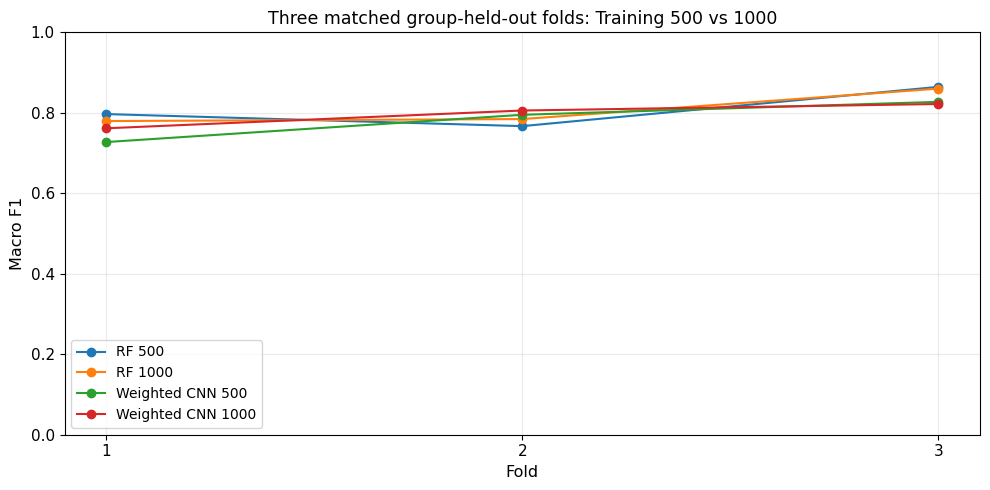

In [6]:
# =================== 05. Compare Grouped Fold Performance ====================

# ----------------------- 1. Summarise Fold Performance -----------------------
cv_summary = cv_fold_results.groupby("model", as_index=False).agg(
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_sd=("macro_f1", "std"),
    balanced_accuracy_mean=("balanced_accuracy", "mean"),
)

display(cv_summary.round(4))

# --------------------- 2. Visualise Matched Fold Scores ----------------------
fig, ax = plt.subplots(figsize=(10, 5))

for name, table in cv_fold_results.groupby("model", sort=False):
    ax.plot(table["fold"], table["macro_f1"], marker="o", label=name)

ax.set(title="Three matched group-held-out folds: Training 500 vs 1000",
       xlabel="Fold", ylabel="Macro F1", ylim=(0, 1),
       xticks=list(range(1, FOLDS + 1)))
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
save_figure(fig, output_dir / "07_cv_fold_macro_f1.png")
plt.show()


**06. Inspect Pooled Out-of-Fold Activity F1**

Compare per-class precision, recall, F1 and support on matched out-of-fold base windows. Review minority stair activities and Shuffling separately.


,model,activity,support,precision,recall,f1
0,RF 500,Walking,3591,0.9272,0.9510,0.9390
1,RF 500,Running,1028,0.9836,0.9903,0.9869
2,RF 500,Shuffling,219,0.4756,0.5342,0.5032
3,RF 500,Stairs ascending,192,0.7310,0.5521,0.6291
4,RF 500,Stairs descending,182,0.7031,0.4945,0.5806
5,RF 500,Standing,2227,0.9382,0.9618,0.9499
6,RF 500,Sitting,5599,0.9969,0.9791,0.9879
7,RF 500,Lying,1163,0.9831,0.9991,0.9910
8,RF 1000,Walking,3591,0.9253,0.9454,0.9353
9,RF 1000,Running,1028,0.9846,0.9922,0.9884


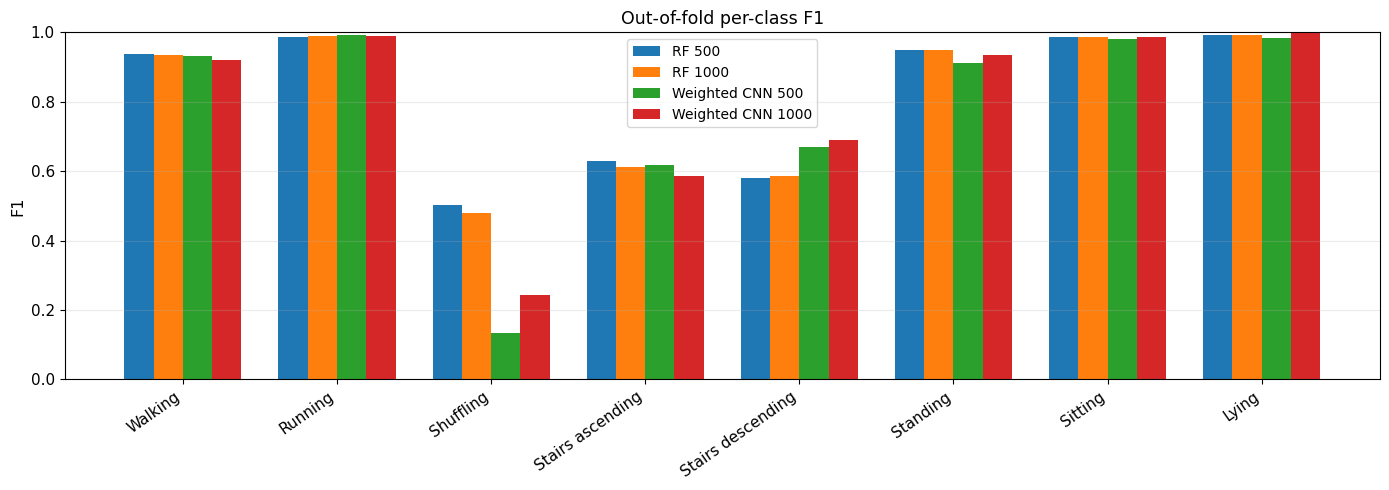

In [7]:
# ================ 06. Inspect Pooled Out-of-Fold Activity F1 =================

# -------------------- 1. Examine Pooled Class Performance --------------------
cv_class_results["activity"] = cv_class_results["class"].map(
    lambda code: ACTIVITY_NAMES[int(code)]
)

display(cv_class_results[[
    "model", "activity", "support", "precision", "recall", "f1"
]].round(4))
fig, ax = plt.subplots(figsize=(14, 5))

# ----------------------- 2. Compare Matched Conditions -----------------------
names = ["RF 500", "RF 1000", "Weighted CNN 500", "Weighted CNN 1000"]
positions = np.arange(len(TASK_CLASSES))
width = 0.19

# ---------------------- 3. Visualise Activity-Level F1 -----------------------
for i, name in enumerate(names):
    score = cv_class_results.loc[cv_class_results["model"] == name, "f1"].to_numpy()
    ax.bar(positions + (i - 1.5)*width, score, width=width, label=name)

ax.set_xticks(positions, [ACTIVITY_NAMES[c] for c in TASK_CLASSES],
              rotation=35, ha="right")
ax.set(title="Out-of-fold per-class F1", ylabel="F1", ylim=(0, 1))
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
save_figure(fig, output_dir / "07_cv_per_class_f1.png")
plt.show()


**07. Compare Paired Grouped Participant Scores**

Use participant-equal fixed eight-class Macro F1 to compare Train caps within each model family, preserving each held-out participant's direction of effect.


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,RF 1000,RF 500,macro_f1_fixed_task,29,0.0071,-0.0026,11,16,2


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN 1000,Weighted CNN 500,macro_f1_fixed_task,29,0.0135,0.0096,20,9,0


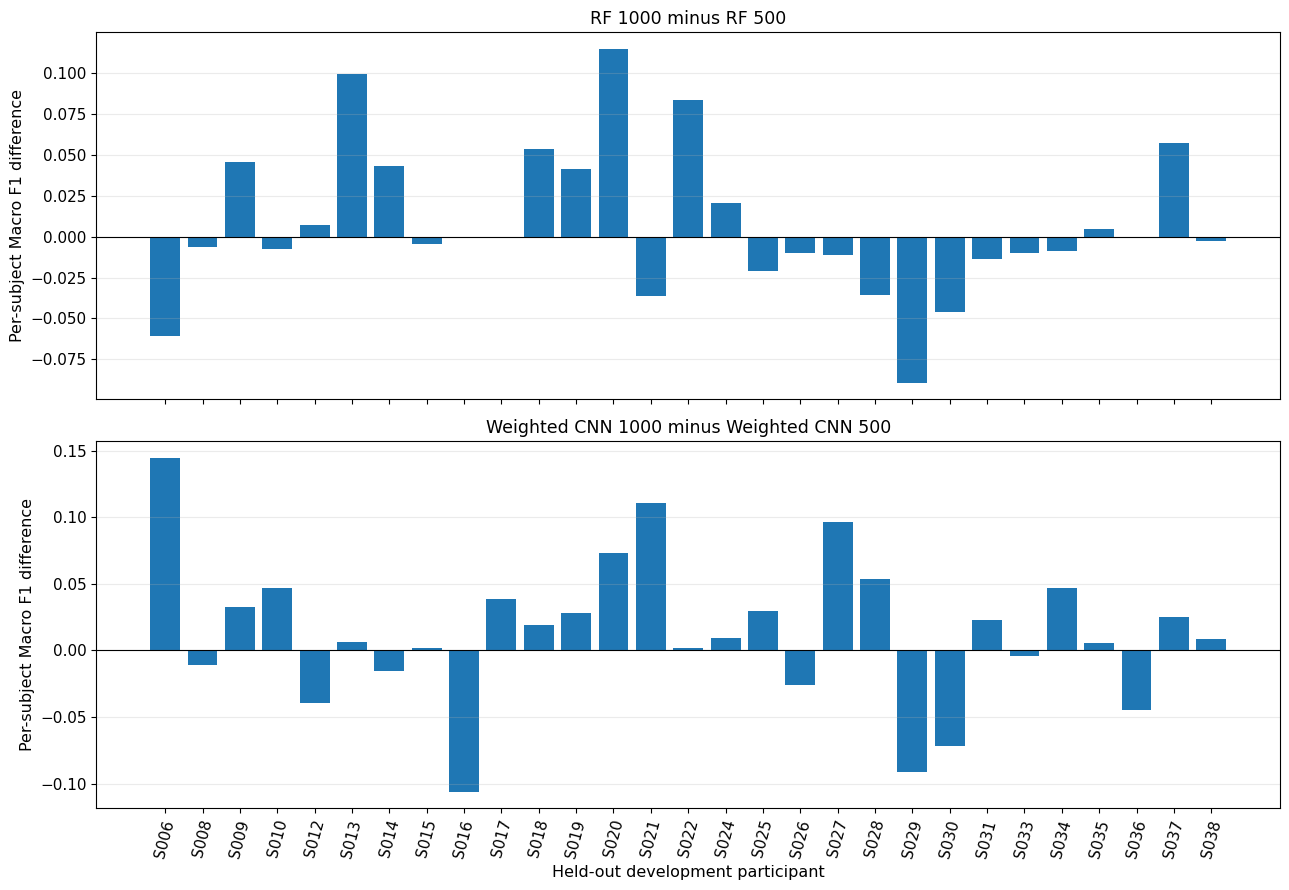

In [8]:
# =============== 07. Compare Paired Grouped Participant Scores ===============

cv_comparisons = [
    ("RF 1000", "RF 500"),
    ("Weighted CNN 1000", "Weighted CNN 500"),
]

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

for ax, (larger, smaller) in zip(axes, cv_comparisons):
    paired, difference = compare_models_by_subject(
        cv_subject_results, model_a=larger, model_b=smaller,
        score_column="macro_f1_fixed_task",
    )
    display(pd.DataFrame([difference]).round(4))
    ax.bar(paired["subject_id"], paired["difference_a_minus_b"])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title=f"{larger} minus {smaller}",
           ylabel="Per-subject Macro F1 difference")
    ax.grid(axis="y", alpha=0.25)

axes[-1].tick_params(axis="x", rotation=75)
axes[-1].set_xlabel("Held-out development participant")
fig.tight_layout()
save_figure(fig, output_dir / "07_cv_paired_participant_differences.png")
plt.show()


**08. Export Matched GroupKFold Evidence**

Save the cohort overview, activity support, fold and participant summaries, pooled class metrics, aligned out-of-fold predictions and paired differences with stable `07_cv_` filenames.


In [9]:
# ================== 08. Export Matched GroupKFold Evidence ===================

overview.to_csv(output_dir / "07_cv_development_cohort_summary.csv", index=False)
counts.rename_axis("activity").reset_index().to_csv(
    output_dir / "07_cv_activity_class_counts.csv", index=False
)
cv_summary.to_csv(output_dir / "07_cv_model_summary.csv", index=False)
cv_fold_results.to_csv(output_dir / "07_cv_fold_metrics.csv", index=False)
cv_subject_results.to_csv(output_dir / "07_cv_subject_metrics.csv", index=False)
cv_class_results.to_csv(output_dir / "07_cv_class_metrics.csv", index=False)
cv_prediction_records.to_csv(output_dir / "07_cv_oof_predictions.csv", index=False)

paired_tables, paired_summaries = [], []
for model_a, model_b in cv_comparisons:
    pair_table, pair_stats = compare_models_by_subject(
        cv_subject_results, model_a=model_a, model_b=model_b,
        score_column="macro_f1_fixed_task",
    )
    pair_table = pair_table.copy()
    pair_table["model_a"] = model_a
    pair_table["model_b"] = model_b
    paired_tables.append(pair_table)
    paired_summaries.append(pair_stats)
pd.concat(paired_tables, ignore_index=True).to_csv(
    output_dir / "07_cv_paired_subjects.csv", index=False
)
pd.DataFrame(paired_summaries).to_csv(
    output_dir / "07_cv_paired_summary.csv", index=False
)
print("Saved grouped Development evidence:", output_dir)


Saved grouped Development evidence: /content/human-movement-intelligence/wearable_activity_recognition/output


**09. Reuse Matched Folds for Fixed-Update Models**

Recreate GroupKFold from the original base window indices and verify that the held-out subject identities match Protocol A. Expanded Train rows come only from that fold's training participants.


In [10]:
# ============== 09. Reuse Matched Folds for Fixed-Update Models ==============

# ------------------- 1. Define Participant-Disjoint Folds --------------------
FOLDS = 3
step_group_folds = list(GroupKFold(n_splits=FOLDS).split(
    np.zeros(len(base_rows)), labels[base_rows], groups=subjects[base_rows]
))
step_fold_design = []

for fold, (tr, va) in enumerate(step_group_folds, start=1):
    train_people = set(subjects[base_rows[tr]])
    validation_people = set(subjects[base_rows[va]])
    if train_people & validation_people:
        raise ValueError("Fixed-update fold has overlapping participants.")
    expanded_train = np.flatnonzero(np.isin(subjects, list(train_people)))
    if not np.isin(base_rows[tr], expanded_train).all():
        raise ValueError("Expanded fold Train does not contain base rows.")
    cv_val = set(cv_fold_results.loc[
        cv_fold_results["fold"] == fold, "validation_subjects"
    ].iloc[0].split(", "))
    if validation_people != cv_val:
        raise ValueError("Fixed-update group membership differs from GroupKFold.")
    step_fold_design.append({
        "fold": fold, "train_people": len(train_people),
        "validation_people": len(validation_people),
        "train_500": len(tr), "train_1000": len(expanded_train),
        "fixed_validation": len(va),
    })

# --------------------- 2. Inspect Fixed Fold Membership ----------------------
display(pd.DataFrame(step_fold_design))

# --------------------------- 3. Export Fold Design ---------------------------
pd.DataFrame(step_fold_design).to_csv(
    output_dir / "07_steps_fold_design.csv", index=False
)


,fold,train_people,validation_people,train_500,train_1000,fixed_validation
0,1,19,10,9201,18201,5000
1,2,19,10,9500,19000,4701
2,3,20,9,9701,19201,4500


**10. Train Weighted CNNs for 400 Updates**

Within the same participant folds, fit weighted CNN 500 and 1,000 for exactly 400 optimiser updates and record predetermined 100-step checkpoints. Retain one original-source-row-aligned out-of-fold prediction per model and base window. This controls updates, not the number of presentations per unique window.


In [11]:
# ================== 10. Train Weighted CNNs for 400 Updates ==================

# ------------------- 1. Configure Matched Optimiser Budget -------------------
MAX_STEPS = 400
EVAL_EVERY = 100

step_fold_records, step_people_frames, step_class_frames = [], [], []
step_histories, step_prediction_frames = [], []

# -------------------- 2. Train Weighted CNN Across Folds ---------------------
for fold, (train_local, validation_local) in enumerate(step_group_folds, start=1):
    train_rows_500 = base_rows[train_local]
    val_rows = base_rows[validation_local]
    train_people = set(subjects[train_rows_500])
    train_rows_1000 = np.flatnonzero(np.isin(subjects, list(train_people)))
    y_val = labels[val_rows]
    for name, selected_train in [
        ("Weighted CNN 500", train_rows_500),
        ("Weighted CNN 1000", train_rows_1000),
    ]:
        print(f"Fold {fold}/{FOLDS} | {name} | {len(selected_train)} Train windows")
        model, history, predicted, statistics = train_temporal_cnn_fixed_steps(
            X_train=X[selected_train], y_train=labels[selected_train],
            X_validation=X[val_rows], y_validation=y_val,
            classes=TASK_CLASSES, max_steps=MAX_STEPS,
            eval_every=EVAL_EVERY, batch_size=128, learning_rate=1e-3,
            seed=42, device=DEVICE, class_weighting="inverse_sqrt",
        )
        step_prediction_frames.append(pd.DataFrame({
            "fold": fold,
            "model": name,
            "source_row": val_rows,
            "subject_id": subjects[val_rows],
            "true_label": y_val,
            "predicted_label": predicted,
        }))
        step_fold_records.append({
            "fold": fold,
            "model": name,
            "train_windows": len(selected_train),
            "validation_windows": len(val_rows),
            "macro_f1": f1_score(
                y_val, predicted, labels=TASK_CLASSES,
                average="macro", zero_division=0,
            ),
            "balanced_accuracy": balanced_accuracy_score(y_val, predicted),
        })
        frame = evaluate_predictions_by_subject(
            y_val, predicted, subjects[val_rows], TASK_CLASSES, name,
        )
        frame.insert(0,"fold",fold)
        step_people_frames.append(frame)
        report = classification_class_report(
            y_val, predicted, classes=TASK_CLASSES,
            class_names=[ACTIVITY_NAMES[code] for code in TASK_CLASSES],
        )
        report["fold"] = fold
        report["model"] = name
        step_class_frames.append(report)
        history["fold"] = fold
        history["model"] = name
        step_histories.append(history)
step_fold_results = pd.DataFrame(step_fold_records)
step_subject_results = pd.concat(step_people_frames, ignore_index=True)
step_class_results = pd.concat(step_class_frames, ignore_index=True)
step_prediction_records = pd.concat(step_prediction_frames, ignore_index=True)

# -------------- 3. Inspect Optimisation and Validation Results ---------------
step_history_table = pd.concat(step_histories, ignore_index=True)
expected_checkpoints = list(range(EVAL_EVERY, MAX_STEPS + 1, EVAL_EVERY))
for (fold, model_name), checkpoints in step_history_table.groupby(
    ["fold", "model"]
):
    if checkpoints["step"].tolist() != expected_checkpoints:
        raise ValueError(
            f"Unexpected fixed-update checkpoint sequence: {fold}, {model_name}."
        )
for model_name, held_out in step_prediction_records.groupby("model"):
    if len(held_out) != len(base_rows) or not held_out["source_row"].is_unique:
        raise ValueError(f"Incomplete fixed-step held-out predictions: {model_name}.")
    if set(held_out["source_row"]) != set(base_rows.tolist()):
        raise ValueError(f"Fixed-step source rows do not match: {model_name}.")
    ordered = held_out.sort_values("source_row")
    if not np.array_equal(
        ordered["true_label"].to_numpy(), labels[np.sort(base_rows)]
    ):
        raise ValueError(f"Fixed-step source labels are misaligned: {model_name}.")

display(step_fold_results.round(4))

# -------------------- 4. Export Matched Training Evidence --------------------
step_fold_results.to_csv(output_dir / "07_steps_fold_metrics.csv", index=False)
step_subject_results.to_csv(output_dir / "07_steps_subject_metrics.csv", index=False)
step_class_results.to_csv(output_dir / "07_steps_class_metrics.csv", index=False)
step_history_table.to_csv(output_dir / "07_steps_training_history.csv", index=False)
step_prediction_records.to_csv(
    output_dir / "07_steps_oof_predictions.csv", index=False
)


Fold 1/3 | Weighted CNN 500 | 9201 Train windows
Step 100/400 | loss=0.8975 | Validation Macro F1=0.5829
Step 200/400 | loss=0.4791 | Validation Macro F1=0.7315
Step 300/400 | loss=0.3274 | Validation Macro F1=0.7647
Step 400/400 | loss=0.2508 | Validation Macro F1=0.7418
Fold 1/3 | Weighted CNN 1000 | 18201 Train windows
Step 100/400 | loss=0.8877 | Validation Macro F1=0.5862
Step 200/400 | loss=0.4701 | Validation Macro F1=0.7494
Step 300/400 | loss=0.3450 | Validation Macro F1=0.7403
Step 400/400 | loss=0.2571 | Validation Macro F1=0.7591
Fold 2/3 | Weighted CNN 500 | 9500 Train windows
Step 100/400 | loss=0.8796 | Validation Macro F1=0.5865
Step 200/400 | loss=0.4411 | Validation Macro F1=0.6819
Step 300/400 | loss=0.3448 | Validation Macro F1=0.7818
Step 400/400 | loss=0.2621 | Validation Macro F1=0.7815
Fold 2/3 | Weighted CNN 1000 | 19000 Train windows
Step 100/400 | loss=0.8686 | Validation Macro F1=0.5879
Step 200/400 | loss=0.4489 | Validation Macro F1=0.6823
Step 300/400 | l

,fold,model,train_windows,validation_windows,macro_f1,balanced_accuracy
0,1,Weighted CNN 500,9201,5000,0.7418,0.8148
1,1,Weighted CNN 1000,18201,5000,0.7591,0.8156
2,2,Weighted CNN 500,9500,4701,0.7815,0.8129
3,2,Weighted CNN 1000,19000,4701,0.7974,0.7734
4,3,Weighted CNN 500,9701,4500,0.7931,0.7785
5,3,Weighted CNN 1000,19201,4500,0.8196,0.8013


**11. Summarise Final-Update Grouped Results**

Report fixed-step Macro F1 and balanced accuracy after the 400th update; preserve variation across folds and avoid choosing the best intermediate checkpoint.


,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean
0,Weighted CNN 1000,0.7921,0.0306,0.7968
1,Weighted CNN 500,0.7721,0.0269,0.8021


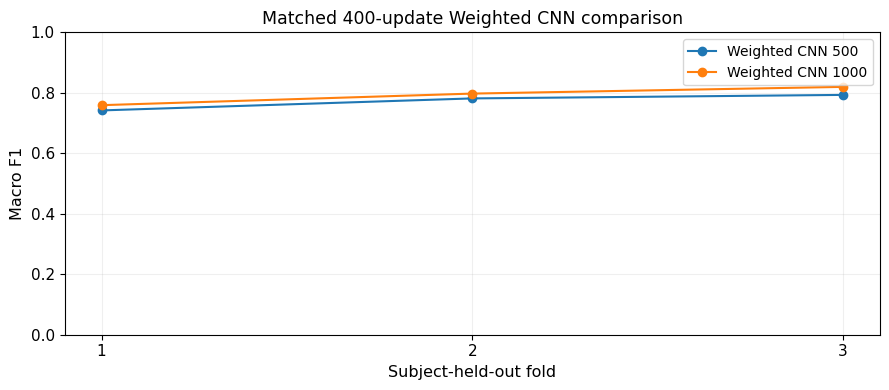

In [12]:
# ================ 11. Summarise Final-Update Grouped Results =================

# ----------------------- 1. Summarise Fold Performance -----------------------
step_summary = step_fold_results.groupby("model", as_index=False).agg(
    macro_f1_mean=("macro_f1","mean"),
    macro_f1_sd=("macro_f1","std"),
    balanced_accuracy_mean=("balanced_accuracy","mean"),
)

display(step_summary.round(4))
step_summary.to_csv(output_dir / "07_steps_model_summary.csv", index=False)

# ------------------------ 2. Visualise Final-Step F1 -------------------------
fig, ax = plt.subplots(figsize=(9, 4))

for name, group in step_fold_results.groupby("model", sort=False):
    ax.plot(group["fold"], group["macro_f1"], marker="o", label=name)

ax.set(title="Matched 400-update Weighted CNN comparison",
       xlabel="Subject-held-out fold", ylabel="Macro F1",
       xticks=list(range(1, FOLDS + 1)), ylim=(0, 1))
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "07_steps_fold_macro_f1.png")
plt.show()


**12. Inspect Predeclared Training Checkpoints**

Plot Validation Macro F1 after 100, 200, 300 and 400 optimiser updates for each fold; these are training trajectories rather than new candidate endpoints.


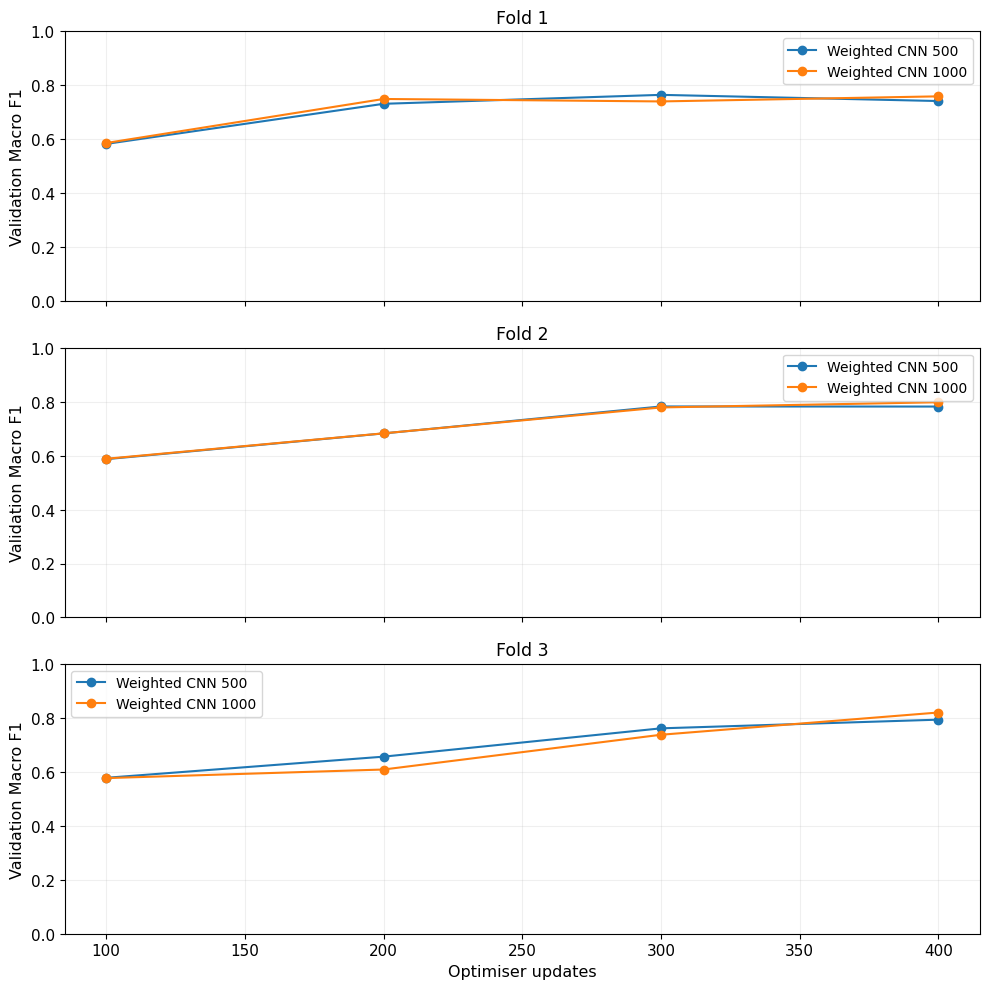

In [13]:
# =============== 12. Inspect Predeclared Training Checkpoints ================

fig, axes = plt.subplots(FOLDS, 1, figsize=(10, 10), sharex=True)

for fold, ax in zip(range(1, FOLDS + 1), axes):
    for name,group in step_history_table.loc[
        step_history_table["fold"] == fold
    ].groupby("model", sort=False):
        ax.plot(group["step"], group["validation_macro_f1"],
                marker="o", label=name)
    ax.set(title=f"Fold {fold}", ylabel="Validation Macro F1", ylim=(0, 1))
    ax.grid(alpha=0.2)
    ax.legend()

axes[-1].set_xlabel("Optimiser updates")
fig.tight_layout()
save_figure(fig, output_dir / "07_steps_validation_trends.png")
plt.show()


**13. Compare Participant and Minority-Class Effects**

Summarise the paired 1,000-minus-500 CNN effect across the 29 held-out Development participants at update 400, then inspect rare-class support and errors by fold.


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN 1000,Weighted CNN 500,macro_f1_fixed_task,29,0.0183,0.0026,17,12,0


,subject_id,score_a,score_b,difference_a_minus_b
0,S006,0.6614,0.6860,-0.0246
1,S008,0.3683,0.3561,0.0122
2,S009,0.3485,0.3460,0.0026
3,S010,0.5260,0.6317,-0.1057
4,S012,0.8399,0.7733,0.0667
5,S013,0.6839,0.7424,-0.0586
6,S014,0.7774,0.7996,-0.0222
7,S015,0.7046,0.7412,-0.0365
8,S016,0.7826,0.6119,0.1707
9,S017,0.5698,0.6449,-0.0751


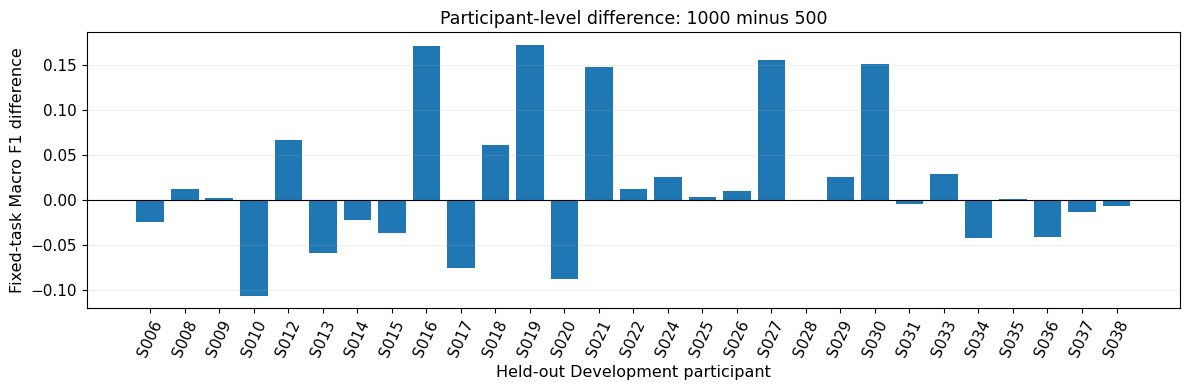

,fold,model,class,support,precision,recall,f1
2,1,Weighted CNN 500,Shuffling,51,0.1045,0.1373,0.1186
3,1,Weighted CNN 500,Stairs ascending,57,0.2781,0.7368,0.4038
4,1,Weighted CNN 500,Stairs descending,46,0.4457,0.8913,0.5942
10,1,Weighted CNN 1000,Shuffling,51,0.1795,0.1373,0.1556
11,1,Weighted CNN 1000,Stairs ascending,57,0.2727,0.7368,0.3981
12,1,Weighted CNN 1000,Stairs descending,46,0.5758,0.8261,0.6786
18,2,Weighted CNN 500,Shuffling,66,0.3750,0.1818,0.2449
19,2,Weighted CNN 500,Stairs ascending,63,0.4015,0.8413,0.5436
20,2,Weighted CNN 500,Stairs descending,52,0.6034,0.6731,0.6364
26,2,Weighted CNN 1000,Shuffling,66,0.2619,0.1667,0.2037


In [14]:
# ============ 13. Compare Participant and Minority-Class Effects =============

# -------------------- 1. Compare Participant-Level Scores --------------------
step_paired, step_paired_summary = compare_models_by_subject(
    step_subject_results, "Weighted CNN 1000", "Weighted CNN 500",
    score_column="macro_f1_fixed_task",  # Compare the same eight classes per participant.
)

display(pd.DataFrame([step_paired_summary]).round(4))
display(step_paired.round(4))

# ------------------- 2. Export Paired Participant Evidence -------------------
step_paired.to_csv(output_dir / "07_steps_paired_subjects.csv", index=False)
pd.DataFrame([step_paired_summary]).to_csv(
    output_dir / "07_steps_paired_summary.csv", index=False
)

# -------------------- 3. Plot Paired Participant Changes ---------------------
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(step_paired["subject_id"], step_paired["difference_a_minus_b"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Participant-level difference: 1000 minus 500",
       xlabel="Held-out Development participant",
       ylabel="Fixed-task Macro F1 difference")

ax.tick_params(axis="x", rotation=65)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "07_steps_subject_differences.png")
plt.show()

# ------------------- 4. Examine Minority-Class Differences -------------------
display(step_class_results.loc[
    step_class_results["class"].isin(
        ["Shuffling","Stairs ascending","Stairs descending"]
    ), ["fold", "model", "class", "support", "precision", "recall", "f1"]
].round(4))


**14. Package Current Notebook Results**

Report the matched-fold and fixed-update configurations, then package the current stage-07 tables and figures as a single downloadable output set.


In [15]:
# =================== 14. Package Current Notebook Results ====================

# --------------------------- 1. Evaluation Summary ---------------------------
print("Participant-disjoint folds:", FOLDS)
print("Final optimiser update:", MAX_STEPS)
print("Evaluation checkpoint interval:", EVAL_EVERY)
print("Held-out Development participants:",
      step_subject_results["subject_id"].nunique())
print("Fixed-step configurations:", ", ".join(step_summary["model"]))

# ------------------- 2. Package Stage-07 Research Outputs --------------------
download_outputs_from_colab(
    folder="wearable_activity_recognition/output", stage="07"
)


Participant-disjoint folds: 3
Final optimiser update: 400
Evaluation checkpoint interval: 100
Held-out Development participants: 29
Fixed-step configurations: Weighted CNN 1000, Weighted CNN 500
------------------------------------------------------------------------
Notebook stage: 07
Files packaged: 24
  + 07_cv_activity_class_counts.csv
  + 07_cv_class_metrics.csv
  + 07_cv_development_cohort_summary.csv
  + 07_cv_fold_macro_f1.png
  + 07_cv_fold_metrics.csv
  + 07_cv_model_summary.csv
  + 07_cv_oof_predictions.csv
  + 07_cv_paired_participant_differences.png
  + 07_cv_paired_subjects.csv
  + 07_cv_paired_summary.csv
  + 07_cv_per_class_f1.png
  + 07_cv_subject_metrics.csv
  + 07_steps_class_metrics.csv
  + 07_steps_fold_design.csv
  + 07_steps_fold_macro_f1.png
  + 07_steps_fold_metrics.csv
  + 07_steps_model_summary.csv
  + 07_steps_oof_predictions.csv
  + 07_steps_paired_subjects.csv
  + 07_steps_paired_summary.csv
  + 07_steps_subject_differences.png
  + 07_steps_subject_metrics

**15. Scientific Interpretation and Research Boundaries**

**Common source design:** The base 500-cap windows are strictly contained in the expanded 1,000-cap Development cohort. Three participant-disjoint folds are shared between the two experiments, and the original reserved assessment participants are excluded.

**Five-epoch grouped protocol:** Random Forest and weighted CNN are evaluated at both Train sizes on identical held-out source windows. The forest uses 30 statistical features and the CNN consumes original temporal signals. Fold averages, pooled activity metrics and participant-equal paired differences are distinct summaries.

**Fixed-optimiser-update protocol:** Weighted CNN models are separately trained for exactly 400 updates with four predetermined evaluation checkpoints. The final-step scores, not earlier maxima, define the comparison. Equal update counts need not imply equal unique-sample exposure or training time.

**Limitations:** These are single-seed, dependent-fold Development experiments with overlapping windows and uneven class support. The results do not establish independent external generalisation, a universal scaling law or real-time deployment performance. Participants S023 and S032 are not evaluated.

**Results:** Current numerical interpretation is added after the integrated notebook has executed and the `07_cv_` and `07_steps_` files have been inspected.
